<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-01/lab-003d-framework-benchmark.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 003d <br>
<hr/>

# Lab 003d — NumPy, JAX, PyTorch and Keras compared

## Four tools, one machine
In Lab 002 we used NumPy, in Lab 003 PyTorch, in Lab 003c JAX. All three manipulate arrays, and two of them
differentiate through the computation. Here we put them — together with **TensorFlow** and **Keras 3** — on the
same tasks and measure three things: the **speed**, i.e. the wall-clock time of the same computation; the cost of
**compilation**, the one-off cost of a just-in-time (JIT) compiler before the first result; and the **code**, i.e. how
the same training step looks in each library.

Timing a program is an experiment like any other: it has systematic errors (other programs running, different
numbers of threads, a compiler working in the background) and statistical errors (the time fluctuates from run to
run). Section 1 therefore fixes the measurement protocol. Sections 2–5 apply it to four tasks of increasing size:
array operations (a matrix multiplication and a chain of elementwise operations), automatic differentiation (a gradient
and a Hessian–vector product), a physics application (Metropolis sampling of the 2D Ising model), and training for one
epoch of a multilayer perceptron (MLP) and a convolutional neural network (CNN) on MNIST. Section 6 shows the same
training step in Flax NNX, PyTorch and Keras side by side. Section 7 collects all measurements in one table and one
figure, Section 8 computes the key ratios, and Section 9 discusses the trade-offs between the libraries. Exercises
close the notebook (Section 10).

> The timings of this notebook are meaningful only under controlled conditions, so a few remarks on running it:
> 1. The timings are meaningful only if nothing else heavy runs on the machine. On a shared computer, pin the notebook
>    to fixed cores, e.g. `taskset -c 0-7 jupyter nbconvert --to notebook --execute Lab_003d_Framework_benchmark.ipynb`.
> 2. The notebook uses the central processing unit (CPU) only (`JAX_PLATFORMS=cpu`, `CUDA_VISIBLE_DEVICES=""`), so that all libraries run on the same hardware.
> 3. Required packages: `numpy`, `pandas`, `matplotlib`, `jax`, `flax`, `optax`, `torch`, `tensorflow`, `keras` (version 3).
>    In Google Colab all of them are pre-installed; the notebook reads the four MNIST files of Lab 016
>    (the constant `MNIST_DIR` in Section 5 points to them).
> 4. Total run time on an 8-core laptop CPU: several minutes.

## 1. Measurement protocol

| Systematic effect | What we do |
|---|---|
| Different numbers of threads | Every library gets the same number of threads `N_THREADS` (8 here). The process is pinned to 8 cores with `taskset`, which caps all libraries at once; in addition each thread pool is set explicitly (table below). |
| Just-in-time compilation | The **first call** of a compiled function includes tracing and compilation. We time it separately and report the **compilation overhead** = first call − typical call. |
| Asynchronous execution | JAX returns before the result is computed (*asynchronous dispatch*). We call `jax.block_until_ready` inside the timed region. PyTorch and TensorFlow on the CPU execute operations synchronously. |
| Fluctuations | Each measurement is repeated; we report the **median** and the interquartile range (IQR, 25th–75th percentile). The median is insensitive to occasional slow repeats caused by other processes. |
| Idle threads competing for cores | `OMP_WAIT_POLICY=PASSIVE`: OpenMP worker threads (used by PyTorch) sleep while waiting for work instead of spinning. On a machine shared with other programs, spinning threads take cores away from the threads doing the work. |
| Other processes | We record the *load average* (the average number of runnable processes over the last minute) at the start and at the end. A load well above `N_THREADS` means the cores were shared and all times are inflated. |
| Unequal work | Same array sizes, same `float32` precision, same algorithm; for training the same architecture, initialisation scheme, optimiser, batch size and batch order, and we report the reached test accuracy next to the time. |

Thread settings used:

| Library | Setting |
|---|---|
| NumPy (OpenBLAS / MKL) | `OPENBLAS_NUM_THREADS`, `MKL_NUM_THREADS`, `OMP_NUM_THREADS` before import, and `threadpoolctl.threadpool_limits` |
| JAX (XLA compiler) | no public thread-count setting; XLA sizes its thread pool from the cores visible to the process, i.e. from the `taskset` mask |
| PyTorch | `torch.set_num_threads(N_THREADS)`, `torch.set_num_interop_threads(1)` |
| TensorFlow | `tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)`, `set_inter_op_parallelism_threads(1)` |

All numbers in this notebook are **CPU-only** results on one laptop (Intel i7-11800H). On a graphics processing unit (GPU), with other
array sizes or with larger models the ranking can change; the protocol carries over, the numbers do not.

The environment variables must be set **before** the libraries are imported, so they come first.

In [1]:
import os, sys, time, json, subprocess, tempfile, gzip, platform

N_THREADS = min(8, len(os.sched_getaffinity(0)))          # cores this process may use (taskset mask), at most 8
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = str(N_THREADS)
os.environ["OMP_WAIT_POLICY"] = "PASSIVE"                  # waiting OpenMP threads sleep instead of spinning
os.environ["JAX_PLATFORMS"] = "cpu"                        # JAX: CPU only
os.environ["CUDA_VISIBLE_DEVICES"] = ""                    # PyTorch / TensorFlow: hide any GPU
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"                   # silence TensorFlow info messages
WORKDIR = tempfile.mkdtemp(prefix="lab003d_")               # scratch files: Keras script, MNIST arrays
os.environ["TORCHINDUCTOR_CACHE_DIR"] = os.path.join(WORKDIR, "inductor")   # empty cache → cold torch.compile

T_START = time.perf_counter()
LOAD_START = os.getloadavg()[0]
print(f"cores visible to this process : {sorted(os.sched_getaffinity(0))}")
print(f"N_THREADS                     : {N_THREADS}")
print(f"1-minute load average at start: {LOAD_START:.1f}  (machine has {os.cpu_count()} logical cores)")

cores visible to this process : [0, 1, 2, 3, 4, 5, 6, 7]
N_THREADS                     : 8
1-minute load average at start: 16.7  (machine has 16 logical cores)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits, threadpool_info
threadpool_limits(N_THREADS)

import jax, jax.numpy as jnp
import flax
from flax import nnx
import optax

import torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(N_THREADS)
torch.set_num_interop_threads(1)

import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
tf.config.threading.set_inter_op_parallelism_threads(1)
import keras

print(f"Python {platform.python_version()} | NumPy {np.__version__} | JAX {jax.__version__} | Flax {flax.__version__} | "
      f"Optax {optax.__version__}\nPyTorch {torch.__version__} | TensorFlow {tf.__version__} | Keras {keras.__version__}")
print("JAX devices      :", jax.devices())
print("PyTorch threads  :", torch.get_num_threads())
print("TF intra-op      :", tf.config.threading.get_intra_op_parallelism_threads())
print("BLAS thread pools:", [(p["internal_api"], p["num_threads"]) for p in threadpool_info()])

Python 3.13.5 | NumPy 2.1.3 | JAX 0.11.0 | Flax 0.12.8 | Optax 0.2.6
PyTorch 2.9.0+cpu | TensorFlow 2.20.0 | Keras 3.12.0


JAX devices      : [CpuDevice(id=0)]
PyTorch threads  : 8
TF intra-op      : 8
BLAS thread pools: [('openblas', 8), ('openmp', 8), ('mkl', 8), ('openmp', 8)]


2026-10-15 23:06:00.087075: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


### The timing function
`bench` calls a function once (the **first call**, which includes any compilation), then `n_rep` more times,
and stores the median and IQR of the repeats. The argument `sync` forces the computation to finish inside the
timed region — for JAX this is `jax.block_until_ready`.

In [3]:
RESULTS = []          # one dict per measurement; becomes the table in Section 7

def bench(task, framework, variant, fn, sync=None, n_rep=7):
    sync = sync or (lambda r: r)
    t0 = time.perf_counter(); out = sync(fn()); first = time.perf_counter() - t0
    ts = []
    for _ in range(n_rep):
        t0 = time.perf_counter(); sync(fn()); ts.append(time.perf_counter() - t0)
    ts = np.array(ts)
    rec = dict(task=task, framework=framework, variant=variant, median_s=np.median(ts),
               q25_s=np.percentile(ts, 25), q75_s=np.percentile(ts, 75), first_call_s=first, n_rep=n_rep)
    RESULTS.append(rec)
    print(f"{framework:11s} {variant:22s} median {1e3*rec['median_s']:9.2f} ms   "
          f"IQR [{1e3*rec['q25_s']:8.2f}, {1e3*rec['q75_s']:8.2f}] ms   first call {1e3*first:9.1f} ms")
    return out

jax_sync = jax.block_until_ready

## 2. Array operations: matrix multiplication and a chain of elementwise operations

The first task is the matrix multiplication $C = AB$ of two $2048\times 2048$ `float32` matrices: $2n^3 \approx 1.7\times 10^{10}$
floating-point operations (FLOP). All libraries hand this to an optimised BLAS-like kernel (Basic Linear Algebra
Subprograms), so we expect similar times; the useful figure of merit is GFLOP/s $= 2n^3/t/10^9$.

The second task is a chain of elementwise operations on $10^7$ numbers,
$$y = \tanh(x)\,e^{-x^2/2} + 0.1\,x^3 - \sin x .$$
Each operation is cheap; the cost is moving 40 MB of data through memory. NumPy and the eager
(*op-by-op*) modes evaluate the formula one operation at a time and store every intermediate array. A compiler
(`jax.jit`, `tf.function(jit_compile=True)`, `torch.compile`) can **fuse** the chain into a single loop that reads
$x$ once and writes $y$ once.

Besides NumPy and the eager modes, we therefore time four variants. In *JAX op-by-op* the `jnp` functions are called directly, and each primitive is dispatched separately.
In *JAX jit* the whole function is compiled by XLA (Accelerated Linear Algebra). *TensorFlow tf.function + XLA* uses `tf.function(..., jit_compile=True)`, the TensorFlow route to the same XLA compiler.
*PyTorch torch.compile* uses PyTorch's compiler (TorchInductor), which generates and compiles C++ code; its cache
starts empty, so the first call is a cold compilation.

In [4]:
N_MAT = 2048
rng = np.random.default_rng(0)
A_np = rng.standard_normal((N_MAT, N_MAT), dtype=np.float32)
B_np = rng.standard_normal((N_MAT, N_MAT), dtype=np.float32)
A_jx, B_jx = jnp.asarray(A_np), jnp.asarray(B_np)
A_pt, B_pt = torch.from_numpy(A_np), torch.from_numpy(B_np)
A_tf, B_tf = tf.constant(A_np), tf.constant(B_np)

task = "matmul 2048×2048"
C_ref = bench(task, "NumPy", "eager", lambda: A_np @ B_np)
mm_jit = jax.jit(lambda a, b: a @ b)
mm_tf = tf.function(lambda a, b: tf.matmul(a, b), jit_compile=True)
C = {"JAX op-by-op": bench(task, "JAX", "op-by-op", lambda: jnp.matmul(A_jx, B_jx), jax_sync),
     "JAX jit":      bench(task, "JAX", "jit", lambda: mm_jit(A_jx, B_jx), jax_sync),
     "PyTorch":      bench(task, "PyTorch", "eager", lambda: A_pt @ B_pt),
     "TF eager":     bench(task, "TensorFlow", "eager", lambda: tf.matmul(A_tf, B_tf)),
     "TF function":  bench(task, "TensorFlow", "tf.function + XLA", lambda: mm_tf(A_tf, B_tf))}

print("\nlargest relative deviation from NumPy:")
for k, v in C.items():
    print(f"  {k:13s} {np.abs(np.asarray(v) - C_ref).max() / np.abs(C_ref).max():.1e}")
print("\nGFLOP/s (median):")
for r in RESULTS:
    if r["task"] == task:
        print(f"  {r['framework']:11s} {r['variant']:18s} {2 * N_MAT**3 / r['median_s'] / 1e9:7.1f}")

NumPy       eager                  median     66.06 ms   IQR [   64.40,    85.61] ms   first call     127.5 ms


JAX         op-by-op               median     86.11 ms   IQR [   78.91,    92.68] ms   first call     158.2 ms


JAX         jit                    median     80.00 ms   IQR [   77.44,    84.31] ms   first call     116.2 ms


PyTorch     eager                  median     98.08 ms   IQR [   86.07,   121.08] ms   first call     197.8 ms


TensorFlow  eager                  median     82.31 ms   IQR [   81.11,    89.19] ms   first call     113.9 ms


I0000 00:00:1792098364.407378 4067263 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


TensorFlow  tf.function + XLA      median     78.82 ms   IQR [   63.03,    85.73] ms   first call     185.2 ms

largest relative deviation from NumPy:
  JAX op-by-op  6.2e-07
  JAX jit       6.2e-07
  PyTorch       5.6e-07
  TF eager      5.6e-07
  TF function   5.4e-07

GFLOP/s (median):
  NumPy       eager                260.0
  JAX         op-by-op             199.5
  JAX         jit                  214.7
  PyTorch     eager                175.2
  TensorFlow  eager                208.7
  TensorFlow  tf.function + XLA    218.0


The deviations are zero or at the level of `float32` round-off, which depends on the order in which each library's
kernel sums the products. Matrix multiplication is limited by arithmetic, and every library calls a
tuned kernel, so the compiler has little to add here.

In [5]:
N_ELEM = 10**7
x_np = rng.standard_normal(N_ELEM, dtype=np.float32)
x_jx, x_pt, x_tf = jnp.asarray(x_np), torch.from_numpy(x_np), tf.constant(x_np)

def make_chain(m):
    # the same formula for every library; m is the module providing tanh, exp, sin
    return lambda x: m.tanh(x) * m.exp(-0.5 * x * x) + 0.1 * x**3 - m.sin(x)

chain_np, chain_jx, chain_pt, chain_tf = make_chain(np), make_chain(jnp), make_chain(torch), make_chain(tf.math)
chain_jit = jax.jit(chain_jx)
chain_tf_xla = tf.function(chain_tf, jit_compile=True)
chain_pt_comp = torch.compile(chain_pt)

task = "elementwise chain 1e7"
y_ref = bench(task, "NumPy", "eager", lambda: chain_np(x_np))
Y = {"JAX op-by-op":  bench(task, "JAX", "op-by-op", lambda: chain_jx(x_jx), jax_sync),
     "JAX jit":       bench(task, "JAX", "jit", lambda: chain_jit(x_jx), jax_sync),
     "PyTorch":       bench(task, "PyTorch", "eager", lambda: chain_pt(x_pt)),
     "torch.compile": bench(task, "PyTorch", "torch.compile", lambda: chain_pt_comp(x_pt)),
     "TF eager":      bench(task, "TensorFlow", "eager", lambda: chain_tf(x_tf)),
     "TF function":   bench(task, "TensorFlow", "tf.function + XLA", lambda: chain_tf_xla(x_tf))}
print("\nlargest absolute deviation from NumPy:")
for k, v in Y.items():
    print(f"  {k:13s} {np.abs(np.asarray(v) - y_ref).max():.1e}")

NumPy       eager                  median   1044.98 ms   IQR [ 1032.40,  1071.87] ms   first call    1043.9 ms


JAX         op-by-op               median    290.82 ms   IQR [  286.73,   294.53] ms   first call     857.8 ms


JAX         jit                    median     78.86 ms   IQR [   75.34,    87.04] ms   first call     175.8 ms


PyTorch     eager                  median    226.26 ms   IQR [  226.16,   231.19] ms   first call     236.4 ms


PyTorch     torch.compile          median     39.11 ms   IQR [   33.24,    43.00] ms   first call   16220.3 ms


TensorFlow  eager                  median    146.88 ms   IQR [  144.00,   154.87] ms   first call     244.2 ms


TensorFlow  tf.function + XLA      median     56.53 ms   IQR [   55.78,    58.35] ms   first call     214.0 ms

largest absolute deviation from NumPy:
  JAX op-by-op  1.9e-06
  JAX jit       1.9e-06
  PyTorch       1.9e-06


  torch.compile 1.9e-06
  TF eager      1.9e-06
  TF function   1.9e-06


All versions agree with NumPy to a few units in the last place of `float32` (for $|y|$ between 8 and 16 one unit is
$2^{-20}\approx 9.5\times10^{-7}$): libraries may use different approximations of `tanh`, `exp` and `sin`. The relative
speed of op-by-op and compiled code is read off in Section 8.

### Thread scaling
Before trusting the timings, we test whether the cores were really available. If they were, more threads should never make an operation slower. We time the PyTorch elementwise
chain with 1, 2, 4 and 8 threads. A time that *grows* with the number of threads signals that the cores are shared with
other programs: an operation split over $n$ threads finishes only when the slowest thread does.

In [6]:
for n in (1, 2, 4, 8):
    if n > N_THREADS: break
    torch.set_num_threads(n)
    chain_pt(x_pt)
    ts = []
    for _ in range(3):
        t0 = time.perf_counter(); chain_pt(x_pt); ts.append(time.perf_counter() - t0)
    print(f"PyTorch elementwise chain, {n} thread(s): median {1e3 * np.median(ts):7.1f} ms")
torch.set_num_threads(N_THREADS)

PyTorch elementwise chain, 1 thread(s): median   452.9 ms


PyTorch elementwise chain, 2 thread(s): median   235.6 ms


PyTorch elementwise chain, 4 thread(s): median   227.0 ms


PyTorch elementwise chain, 8 thread(s): median   241.5 ms


## 3. Automatic differentiation: gradient and Hessian–vector product

We take a function of a $1000\times 1000$ matrix $W$ ($10^6$ parameters) with fixed data $X\in\mathbb{R}^{256\times1000}$:
$$L(W) = \frac{1}{256}\sum_{b,j}\log\cosh\big((XW)_{bj}\big) + \frac{\lambda}{2}\lVert W\rVert^2,\qquad \lambda = 10^{-3}.$$
Both derivatives are known in closed form, so we can check every library:
$$\nabla L = \tfrac{1}{256}X^{\mathsf T}\tanh(XW) + \lambda W,\qquad
H V = \tfrac{1}{256}X^{\mathsf T}\big[(1-\tanh^2(XW))\odot (XV)\big] + \lambda V .$$
The **Hessian–vector product** (HVP) $HV$ costs about as much as a few gradients, although the Hessian itself has
$10^{12}$ entries. Each library builds it differently. JAX uses forward-over-reverse differentiation, `jax.jvp(jax.grad(L), (W,), (V,))`.
PyTorch uses a double backward pass, `torch.autograd.grad(..., create_graph=True)` followed by a second `grad`.
TensorFlow uses two nested `tf.GradientTape`s.

In [7]:
D, NB, LAM = 1000, 256, 1e-3
X_np = (rng.standard_normal((NB, D)) / np.sqrt(D)).astype(np.float32)
W_np = (rng.standard_normal((D, D)) / np.sqrt(D) * 3).astype(np.float32)
V_np = rng.standard_normal((D, D)).astype(np.float32)

# closed-form references (float64)
Z = X_np.astype(np.float64) @ W_np
g_ref = X_np.T @ np.tanh(Z) / NB + LAM * W_np
hv_ref = X_np.T @ ((1 - np.tanh(Z)**2) * (X_np @ V_np.astype(np.float64))) / NB + LAM * V_np

def make_loss(m, X):
    total = m.reduce_sum if m is tf.math else m.sum              # the same formula for every library
    return lambda W: total(m.log(m.cosh(X @ W))) / NB + 0.5 * LAM * total(W * W)

# --- JAX ---
X_jx, W_jx, V_jx = map(jnp.asarray, (X_np, W_np, V_np))
L_jx = make_loss(jnp, X_jx)
grad_jx = jax.grad(L_jx)
hvp_jx = lambda W, V: jax.jvp(jax.grad(L_jx), (W,), (V,))[1]
grad_jx_jit, hvp_jx_jit = jax.jit(grad_jx), jax.jit(hvp_jx)

# --- PyTorch ---
X_pt, W_pt, V_pt = map(torch.from_numpy, (X_np, W_np, V_np))
L_pt = make_loss(torch, X_pt)
def grad_pt(W):
    W = W.detach().requires_grad_(True)
    (g,) = torch.autograd.grad(L_pt(W), W)
    return g
def hvp_pt(W, V):
    W = W.detach().requires_grad_(True)
    (g,) = torch.autograd.grad(L_pt(W), W, create_graph=True)
    (hv,) = torch.autograd.grad(g, W, grad_outputs=V)
    return hv

# --- TensorFlow ---
X_tf, W_tf, V_tf = map(tf.constant, (X_np, W_np, V_np))
L_tf = make_loss(tf.math, X_tf)
def grad_tf(W):
    with tf.GradientTape() as tape:
        tape.watch(W); L = L_tf(W)
    return tape.gradient(L, W)
def hvp_tf(W, V):
    with tf.GradientTape() as outer:
        outer.watch(W)
        with tf.GradientTape() as inner:
            inner.watch(W); L = L_tf(W)
        gV = tf.reduce_sum(inner.gradient(L, W) * V)
    return outer.gradient(gV, W)
grad_tf_xla = tf.function(grad_tf, jit_compile=True)
hvp_tf_xla = tf.function(hvp_tf, jit_compile=True)

In [8]:
def rel_err(a, ref): return np.abs(np.asarray(a) - ref).max() / np.abs(ref).max()

task = "gradient (1e6 params)"
G = {"JAX op-by-op": bench(task, "JAX", "op-by-op", lambda: grad_jx(W_jx), jax_sync),
     "JAX jit":      bench(task, "JAX", "jit", lambda: grad_jx_jit(W_jx), jax_sync),
     "PyTorch":      bench(task, "PyTorch", "eager", lambda: grad_pt(W_pt)),
     "TF eager":     bench(task, "TensorFlow", "eager", lambda: grad_tf(W_tf)),
     "TF function":  bench(task, "TensorFlow", "tf.function + XLA", lambda: grad_tf_xla(W_tf))}
print()
task = "Hessian-vector product"
H = {"JAX op-by-op": bench(task, "JAX", "op-by-op", lambda: hvp_jx(W_jx, V_jx), jax_sync),
     "JAX jit":      bench(task, "JAX", "jit", lambda: hvp_jx_jit(W_jx, V_jx), jax_sync),
     "PyTorch":      bench(task, "PyTorch", "eager", lambda: hvp_pt(W_pt, V_pt)),
     "TF eager":     bench(task, "TensorFlow", "eager", lambda: hvp_tf(W_tf, V_tf)),
     "TF function":  bench(task, "TensorFlow", "tf.function + XLA", lambda: hvp_tf_xla(W_tf, V_tf))}

print("\nrelative error with respect to the closed form:   gradient     HVP")
for k in G:
    print(f"  {k:13s}                                    {rel_err(G[k], g_ref):.1e}    {rel_err(H[k], hv_ref):.1e}")

JAX         op-by-op               median     36.94 ms   IQR [   29.75,    41.22] ms   first call    1518.2 ms


JAX         jit                    median     12.81 ms   IQR [   12.33,    14.25] ms   first call     159.7 ms


PyTorch     eager                  median     34.31 ms   IQR [   28.82,    38.16] ms   first call      55.3 ms


TensorFlow  eager                  median     33.85 ms   IQR [   32.24,    37.31] ms   first call     229.4 ms


TensorFlow  tf.function + XLA      median     15.30 ms   IQR [   14.19,    17.93] ms   first call     218.5 ms



JAX         op-by-op               median     61.35 ms   IQR [   55.05,    64.33] ms   first call    1067.2 ms


JAX         jit                    median     17.06 ms   IQR [   16.30,    22.70] ms   first call     178.1 ms


PyTorch     eager                  median     62.00 ms   IQR [   60.21,    64.66] ms   first call      66.0 ms


TensorFlow  eager                  median     70.80 ms   IQR [   70.11,    72.08] ms   first call     100.1 ms


TensorFlow  tf.function + XLA      median     18.65 ms   IQR [   17.10,    22.14] ms   first call     305.9 ms

relative error with respect to the closed form:   gradient     HVP
  JAX op-by-op                                     6.1e-07    5.5e-07
  JAX jit                                          6.1e-07    5.5e-07
  PyTorch                                          5.8e-07    5.8e-07
  TF eager                                         6.7e-07    5.2e-07
  TF function                                      5.8e-07    5.1e-07


All libraries agree with the closed-form derivatives to `float32` precision. The derivative code is generated
automatically from the code of $L$; only the *style* differs — function transformations in JAX (`grad`, `jvp`),
a recorded graph in PyTorch and TensorFlow.

## 4. Physics: Metropolis sampling of the 2D Ising model

The Ising model on an $L\times L$ periodic lattice, $E = -\sum_{\langle ij\rangle} s_i s_j$, $s_i=\pm1$, has a phase transition
at $T_c = 2/\ln(1+\sqrt2) \approx 2.269$ (units $J = k_B = 1$). A **checkerboard Metropolis sweep** colours the lattice like a
chessboard; sites of one colour do not interact with each other, so all of them can be updated at once. For the sites of one colour we
compute the neighbour sum $h_i$ with four `roll`s, so that the energy change of flipping $s_i$ is $\Delta E_i = 2 s_i h_i$, and
flip every site with probability $\min(1, e^{-\Delta E_i/T})$; then we repeat this for the other colour.

We run **64 independent chains** of $64\times64$ spins for 200 sweeps from the ordered state $s_i=+1$, discard the first 50
sweeps and average $|m| = |\frac{1}{L^2}\sum_i s_i|$ over the remaining 150. The error bar is the standard deviation of the
64 chain averages divided by $\sqrt{64}$ (chains are independent). Temperatures: $T = 2.0 < T_c$ and $T = 3.0 > T_c$.
For $T<T_c$ the infinite-lattice result of Onsager and Yang, $m = [1-\sinh^{-4}(2/T)]^{1/8}$, is a reference.

The three implementations follow the style of each library. The NumPy version is vectorised over chains and sites, with a Python loop over sweeps.
The JAX version is the code for *one chain*: `jax.lax.scan` replaces the loop over sweeps, `jax.vmap` adds the chain dimension, and `jax.jit` compiles everything into one program.
The PyTorch version is the NumPy code with `torch` functions, executed eagerly.

Each library has its own random-number generator, so the chains differ; the averages must agree within errors.

In [9]:
L_ISING, N_CHAINS, N_SWEEPS, N_THERM = 64, 64, 200, 50
T_LOW, T_HIGH = 2.0, 3.0
ii, jj = np.indices((L_ISING, L_ISING))
MASKS_NP = [((ii + jj) % 2 == c) for c in (0, 1)]           # the two checkerboard colours

def ising_numpy(T, seed=0):
    rng = np.random.default_rng(seed)
    s = np.ones((N_CHAINS, L_ISING, L_ISING), np.float32)
    absm = np.empty((N_SWEEPS, N_CHAINS), np.float32)
    for t in range(N_SWEEPS):
        for mask in MASKS_NP:
            h = np.roll(s, 1, 1) + np.roll(s, -1, 1) + np.roll(s, 1, 2) + np.roll(s, -1, 2)
            u = rng.random(s.shape, dtype=np.float32)
            s = np.where(mask & (u < np.exp(-2.0 * s * h / T)), -s, s)
        absm[t] = np.abs(s.mean(axis=(1, 2)))
    return absm

MASKS_JX = [jnp.asarray(m) for m in MASKS_NP]
def ising_one_chain(key, T):
    def half_sweep(s, key, mask):
        h = jnp.roll(s, 1, 0) + jnp.roll(s, -1, 0) + jnp.roll(s, 1, 1) + jnp.roll(s, -1, 1)
        u = jax.random.uniform(key, s.shape)
        return jnp.where(mask & (u < jnp.exp(-2.0 * s * h / T)), -s, s)
    def sweep(s, key):
        k0, k1 = jax.random.split(key)
        s = half_sweep(half_sweep(s, k0, MASKS_JX[0]), k1, MASKS_JX[1])
        return s, jnp.abs(s.mean())
    _, absm = jax.lax.scan(sweep, jnp.ones((L_ISING, L_ISING)), jax.random.split(key, N_SWEEPS))
    return absm                                                # shape (N_SWEEPS,)
ising_jax = jax.jit(jax.vmap(ising_one_chain, in_axes=(0, None), out_axes=1))   # T is traced: one compilation for all T

MASKS_PT = [torch.from_numpy(m) for m in MASKS_NP]
def ising_torch(T, seed=0):
    g = torch.Generator().manual_seed(seed)
    s = torch.ones((N_CHAINS, L_ISING, L_ISING))
    absm = torch.empty((N_SWEEPS, N_CHAINS))
    for t in range(N_SWEEPS):
        for mask in MASKS_PT:
            h = s.roll(1, 1) + s.roll(-1, 1) + s.roll(1, 2) + s.roll(-1, 2)
            u = torch.rand(s.shape, generator=g)
            s = torch.where(mask & (u < torch.exp(-2.0 * s * h / T)), -s, s)
        absm[t] = s.mean(dim=(1, 2)).abs()
    return absm

keys = jax.random.split(jax.random.key(0), N_CHAINS)
task = "Ising 64 chains × 64², 200 sweeps"
ABSM = {}
ABSM[("NumPy", T_LOW)] = bench(task, "NumPy", "vectorised", lambda: ising_numpy(T_LOW), n_rep=2)
ABSM[("JAX", T_LOW)] = bench(task, "JAX", "jit + scan + vmap", lambda: ising_jax(keys, T_LOW), jax_sync, n_rep=2)
ABSM[("PyTorch", T_LOW)] = bench(task, "PyTorch", "eager", lambda: ising_torch(T_LOW), n_rep=2)
ABSM[("NumPy", T_HIGH)] = ising_numpy(T_HIGH)
ABSM[("JAX", T_HIGH)] = ising_jax(keys, T_HIGH)
ABSM[("PyTorch", T_HIGH)] = ising_torch(T_HIGH)

NumPy       vectorised             median   1777.81 ms   IQR [ 1671.10,  1884.51] ms   first call    1889.6 ms


JAX         jit + scan + vmap      median   4547.54 ms   IQR [ 4531.95,  4563.13] ms   first call    7557.9 ms


PyTorch     eager                  median   2905.48 ms   IQR [ 2881.06,  2929.90] ms   first call    2769.8 ms


     T framework  mean_abs_m  error
2.0000     NumPy      0.9117 0.0003
2.0000       JAX      0.9108 0.0003
2.0000   PyTorch      0.9110 0.0003
3.0000     NumPy      0.0427 0.0005
3.0000       JAX      0.0419 0.0007
3.0000   PyTorch      0.0423 0.0006

Onsager-Yang (L → ∞) at T = 2.0: m = 0.9113

largest pairwise deviation in units of the combined error:
  T = 2.0: 2.12 σ
  T = 3.0: 0.87 σ


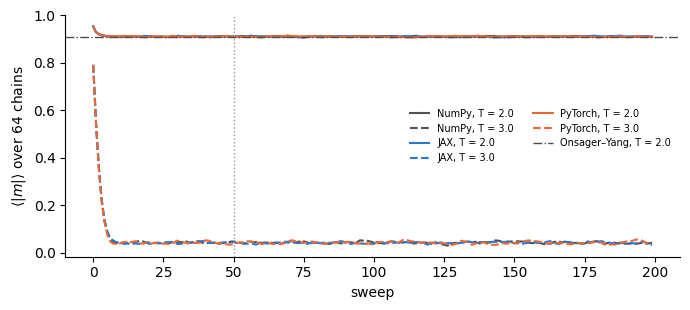

In [10]:
def chain_estimate(absm):
    per_chain = np.asarray(absm)[N_THERM:].mean(axis=0)       # time average in each chain
    return per_chain.mean(), per_chain.std(ddof=1) / np.sqrt(len(per_chain))

m_onsager = (1 - np.sinh(2 / T_LOW)**-4)**(1 / 8)
rows = []
for T in (T_LOW, T_HIGH):
    for fw in ("NumPy", "JAX", "PyTorch"):
        mean, err = chain_estimate(ABSM[(fw, T)])
        rows.append(dict(T=T, framework=fw, mean_abs_m=mean, error=err))
ising_df = pd.DataFrame(rows)
print(ising_df.to_string(index=False, float_format="%.4f"))
print(f"\nOnsager-Yang (L → ∞) at T = {T_LOW}: m = {m_onsager:.4f}")

print("\nlargest pairwise deviation in units of the combined error:")
for T in (T_LOW, T_HIGH):
    d = ising_df[ising_df["T"] == T]
    z = max(abs(a.mean_abs_m - b.mean_abs_m) / np.hypot(a.error, b.error)
            for _, a in d.iterrows() for _, b in d.iterrows() if a.framework < b.framework)
    print(f"  T = {T}: {z:.2f} σ")

fig, ax = plt.subplots(figsize=(7, 3.2))
for fw, c in zip(("NumPy", "JAX", "PyTorch"), ("#52514e", "#2a78d6", "#eb6834")):
    for T, ls in ((T_LOW, "-"), (T_HIGH, "--")):
        ax.plot(np.asarray(ABSM[(fw, T)]).mean(axis=1), ls, color=c, lw=1.5, label=f"{fw}, T = {T}")
ax.axvline(N_THERM, color="0.6", lw=1, ls=":")
ax.axhline(m_onsager, color="0.3", lw=1, ls="-.", label="Onsager–Yang, T = 2.0")
ax.set_xlabel("sweep"); ax.set_ylabel(r"$\langle |m| \rangle$ over 64 chains")
ax.legend(fontsize=7, ncol=2, frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

The three implementations sample the same distribution: at both temperatures the averages agree within the statistical
error. With three pairs compared per temperature, a largest deviation of up to about 2σ occurs by chance; a deviation above
3σ would point to a bug. Below $T_c$ the finite lattice gives a
value close to the infinite-lattice $m$; above $T_c$, $\langle|m|\rangle$ is small and nonzero only because $L$ is finite
(it scales as $L^{-1}$ in the disordered phase).

### Cost of random-number generation
Each sweep draws one uniform random number per site, $2\times 200\times 64\times 64^2 \approx 1.0\times10^8$ numbers per run.
NumPy uses the PCG64 generator (permuted congruential generator, 64-bit output); JAX by default uses Threefry, a *counter-based* generator designed so that independent
streams can be split off a key deterministically and in parallel (`jax.random.split`). To see how much of the sampling time goes into random numbers, we time the generation of the same
amount of random numbers alone.

In [11]:
shape = (2 * N_SWEEPS, N_CHAINS, L_ISING, L_ISING)
rng_np = np.random.default_rng(0)
uniform_jax = jax.jit(lambda k: jax.random.uniform(k, shape))
g_pt = torch.Generator().manual_seed(0)
for name, fn, sync in (("NumPy  (PCG64)", lambda: rng_np.random(shape, dtype=np.float32), None),
                       ("JAX    (Threefry, jit)", lambda: uniform_jax(jax.random.key(1)), jax_sync),
                       ("PyTorch (Mersenne Twister)", lambda: torch.rand(shape, generator=g_pt), None)):
    sync = sync or (lambda r: r)
    sync(fn()); ts = []
    for _ in range(2):
        t0 = time.perf_counter(); sync(fn()); ts.append(time.perf_counter() - t0)
    print(f"{name:27s} {np.prod(shape):.2e} uniform numbers: {np.median(ts):6.2f} s")

NumPy  (PCG64)              1.05e+08 uniform numbers:   0.54 s


JAX    (Threefry, jit)      1.05e+08 uniform numbers:   1.91 s


PyTorch (Mersenne Twister)  1.05e+08 uniform numbers:   1.17 s


## 5. Training: one epoch of an MLP and a CNN on MNIST

MNIST (Modified National Institute of Standards and Technology database) contains 70 000 grey-scale images of
handwritten digits, $28\times28$ pixels: 60 000 for training, 10 000 for testing. We train two models, identical in every library.
The **MLP** (multilayer perceptron) has layers $784 \to 256 \to 256 \to 10$ with rectified linear unit (ReLU) activations.
The **CNN** (convolutional neural network) is Conv $3\times3$, 16 channels → ReLU → max-pool 2 → Conv $3\times3$, 32 channels →
ReLU → max-pool 2 → Dense 128 → ReLU → Dense 10, without padding.

Common settings: Glorot-uniform initialisation of all weights, zero biases; Adam with learning rate $10^{-3}$ and
$\varepsilon = 10^{-8}$; cross-entropy loss on logits; batch size 128; the same random order of the training images
for every library; 468 full batches = one epoch (the last 96 images are dropped so that all batches have the same shape
and the compiled step is reused).

Each run starts with a warm-up of 10 batches (from a different permutation), which includes the compilation of the training step and is reported as the first-call time.
Then one epoch is timed, split into 6 chunks of 78 batches; the epoch time is the sum, and the spread is the IQR of the 6 chunk times (scaled to an epoch).
Finally, the test accuracy on the 10 000 test images is measured.
Accuracy after one epoch tells us whether the libraries did the same job — a fast but badly trained model would not be a fair comparison.

In [12]:
MNIST_DIR = "../../Lecture_5/Notebooks/data/MNIST_raw"

def read_idx(name, offset):
    with gzip.open(os.path.join(MNIST_DIR, name)) as f:
        return np.frombuffer(f.read(), np.uint8, offset=offset)

x_train = (read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 28, 28, 1) / 255).astype(np.float32)
y_train = read_idx("train-labels-idx1-ubyte.gz", 8).astype(np.int32)
x_test = (read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 28, 28, 1) / 255).astype(np.float32)
y_test = read_idx("t10k-labels-idx1-ubyte.gz", 8).astype(np.int32)

BATCH, N_STEPS, N_WARM, N_CHUNKS, LR, EPS = 128, 60000 // 128, 10, 6, 1e-3, 1e-8
perm_rng = np.random.default_rng(1)
WARM_IDX = perm_rng.permutation(len(x_train))[:N_WARM * BATCH].reshape(N_WARM, BATCH)
EPOCH_IDX = perm_rng.permutation(len(x_train))[:N_STEPS * BATCH].reshape(N_STEPS, BATCH)
CHUNKS = np.array_split(EPOCH_IDX, N_CHUNKS)
print(f"train {x_train.shape}, test {x_test.shape}; {N_STEPS} batches of {BATCH} per epoch, chunks of {len(CHUNKS[0])}")

TRAIN = []           # one dict per training run

def time_training(framework, model_name, run_steps, evaluate):
    # run_steps(idx) trains on the batches idx[k] and returns when all work is finished
    t0 = time.perf_counter(); run_steps(WARM_IDX); t_warm = time.perf_counter() - t0
    chunk_t = []
    for idx in CHUNKS:
        t0 = time.perf_counter(); run_steps(idx); chunk_t.append(time.perf_counter() - t0)
    return record_training(framework, model_name, t_warm, chunk_t, evaluate())

def record_training(framework, model_name, t_warm, chunk_t, acc):
    chunk_t = np.array(chunk_t)
    per_epoch = N_CHUNKS * chunk_t
    rec = dict(task=f"{model_name}: 1 epoch", framework=framework, variant="train", median_s=chunk_t.sum(),
               q25_s=np.percentile(per_epoch, 25), q75_s=np.percentile(per_epoch, 75),
               first_call_s=t_warm, step_time_s=chunk_t.sum() / N_STEPS, test_acc=acc, n_rep=N_CHUNKS)
    TRAIN.append(rec)
    print(f"{framework:16s} {model_name}: epoch {rec['median_s']:6.2f} s   ({1e3*rec['step_time_s']:5.1f} ms/step)   "
          f"warm-up {t_warm:5.2f} s   test accuracy {acc:.4f}")

train (60000, 28, 28, 1), test (10000, 28, 28, 1); 468 batches of 128 per epoch, chunks of 78


### Flax NNX
The model is a Python class (as in PyTorch); `nnx.jit` compiles the whole training step — forward pass, gradient and
Adam update — into one XLA program.

In [13]:
glorot = nnx.initializers.glorot_uniform()

class MLP_nnx(nnx.Module):
    def __init__(self, rngs):
        self.l1 = nnx.Linear(784, 256, kernel_init=glorot, rngs=rngs)
        self.l2 = nnx.Linear(256, 256, kernel_init=glorot, rngs=rngs)
        self.l3 = nnx.Linear(256, 10, kernel_init=glorot, rngs=rngs)
    def __call__(self, x):
        x = x.reshape(x.shape[0], -1)
        return self.l3(nnx.relu(self.l2(nnx.relu(self.l1(x)))))

class CNN_nnx(nnx.Module):
    def __init__(self, rngs):
        self.c1 = nnx.Conv(1, 16, (3, 3), padding="VALID", kernel_init=glorot, rngs=rngs)
        self.c2 = nnx.Conv(16, 32, (3, 3), padding="VALID", kernel_init=glorot, rngs=rngs)
        self.d1 = nnx.Linear(5 * 5 * 32, 128, kernel_init=glorot, rngs=rngs)
        self.d2 = nnx.Linear(128, 10, kernel_init=glorot, rngs=rngs)
    def __call__(self, x):                                     # x: (batch, 28, 28, 1)
        x = nnx.max_pool(nnx.relu(self.c1(x)), (2, 2), (2, 2))
        x = nnx.max_pool(nnx.relu(self.c2(x)), (2, 2), (2, 2))
        return self.d2(nnx.relu(self.d1(x.reshape(x.shape[0], -1))))

@nnx.jit
def train_step_nnx(model, optimizer, x, y):
    def loss_fn(model):
        return optax.softmax_cross_entropy_with_integer_labels(model(x), y).mean()
    loss, grads = nnx.value_and_grad(loss_fn)(model)
    optimizer.update(model, grads)
    return loss

@nnx.jit
def predict_nnx(model, x):
    return model(x).argmax(-1)

def train_nnx(model_cls, name):
    model = model_cls(nnx.Rngs(0))
    optimizer = nnx.Optimizer(model, optax.adam(LR, eps=EPS), wrt=nnx.Param)
    def run_steps(idx):
        for b in idx:
            loss = train_step_nnx(model, optimizer, x_train[b], y_train[b])
        jax.block_until_ready(loss)
    def evaluate():
        pred = np.concatenate([np.asarray(predict_nnx(model, x_test[i:i + 1000])) for i in range(0, 10000, 1000)])
        return float((pred == y_test).mean())
    n_par = sum(p.size for p in jax.tree.leaves(nnx.state(model, nnx.Param)))
    print(f"{name}: {n_par} parameters")
    return time_training("JAX / Flax NNX", name, run_steps, evaluate)

train_nnx(MLP_nnx, "MLP"); train_nnx(CNN_nnx, "CNN");

MLP: 269322 parameters


JAX / Flax NNX   MLP: epoch   1.52 s   (  3.2 ms/step)   warm-up  0.74 s   test accuracy 0.9625


CNN: 108618 parameters


JAX / Flax NNX   CNN: epoch  26.59 s   ( 56.8 ms/step)   warm-up  2.36 s   test accuracy 0.9770


### PyTorch
PyTorch stores images as (batch, channels, height, width); we transpose the arrays once, outside the timed region.
The default PyTorch initialisation differs from Glorot, so we re-initialise the weights.

In [14]:
x_train_pt = torch.from_numpy(np.ascontiguousarray(x_train.transpose(0, 3, 1, 2)))
x_test_pt = torch.from_numpy(np.ascontiguousarray(x_test.transpose(0, 3, 1, 2)))
y_train_pt = torch.from_numpy(y_train.astype(np.int64))

def mlp_torch():
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))

def cnn_torch():
    return nn.Sequential(nn.Conv2d(1, 16, 3), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(5 * 5 * 32, 128), nn.ReLU(), nn.Linear(128, 10))

def glorot_init_(model):
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    return model

def train_torch(builder, name):
    torch.manual_seed(0)
    model = glorot_init_(builder())
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, eps=EPS)
    def run_steps(idx):
        model.train()
        for b in idx:
            b = torch.from_numpy(b)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(x_train_pt[b]), y_train_pt[b])
            loss.backward()
            optimizer.step()
    def evaluate():
        model.eval()
        with torch.no_grad():
            pred = model(x_test_pt).argmax(1).numpy()
        return float((pred == y_test).mean())
    print(f"{name}: {sum(p.numel() for p in model.parameters())} parameters")
    return time_training("PyTorch", name, run_steps, evaluate)

train_torch(mlp_torch, "MLP"); train_torch(cnn_torch, "CNN");

MLP: 269322 parameters


PyTorch          MLP: epoch   6.16 s   ( 13.2 ms/step)   warm-up  0.13 s   test accuracy 0.9619
CNN: 108618 parameters


PyTorch          CNN: epoch  26.58 s   ( 56.8 ms/step)   warm-up  0.30 s   test accuracy 0.9796


### Keras 3 with three backends, each in its own process
Keras 3 is a front end: the same model code runs on JAX, PyTorch or TensorFlow, chosen by the environment variable
`KERAS_BACKEND`. Keras reads it **once, at import time**, and a Python module is imported only once per process — so
one process can use only one backend. (Importing JAX, PyTorch and TensorFlow into the same process would also mix three
thread pools, which would bias the timings.) We therefore write a small script, run it once per backend with
`subprocess`, and collect the results as JSON. The child processes inherit the `taskset` mask and get the same thread settings.

Keras trains with `model.fit`, which compiles the step automatically (`jit_compile="auto"`: XLA for the JAX
backend; `tf.function` graph execution *without* XLA for the TensorFlow backend, because Keras switches XLA off on machines
without a GPU; plain eager execution for the PyTorch backend). The script reports the value of `model.jit_compile` it used.

In [15]:
KERAS_SCRIPT = r"""
import os, sys, json, time
backend, n_threads, data_path = sys.argv[1], int(sys.argv[2]), sys.argv[3]
os.environ["KERAS_BACKEND"] = backend                       # must be set before `import keras`
if backend == "torch":
    import torch
    torch.set_num_threads(n_threads); torch.set_num_interop_threads(1)
if backend == "tensorflow":
    import tensorflow as tf
    tf.config.threading.set_intra_op_parallelism_threads(n_threads)
    tf.config.threading.set_inter_op_parallelism_threads(1)
import numpy as np
import keras
from keras import layers

d = np.load(data_path)
x_train, y_train, x_test, y_test = d["x_train"], d["y_train"], d["x_test"], d["y_test"]
warm_idx, chunks = d["warm_idx"], [d[k] for k in sorted(k for k in d.files if k.startswith("chunk_"))]

def build(kind):
    if kind == "MLP":
        body = [layers.Flatten(), layers.Dense(256, activation="relu"),
                layers.Dense(256, activation="relu"), layers.Dense(10)]
    else:
        body = [layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(2),
                layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(2),
                layers.Flatten(), layers.Dense(128, activation="relu"), layers.Dense(10)]
    return keras.Sequential([keras.Input((28, 28, 1))] + body)  # Keras default init: Glorot uniform, zero bias

out = []
for kind in ("MLP", "CNN"):
    keras.utils.set_random_seed(0)
    model = build(kind)
    model.compile(optimizer=keras.optimizers.Adam(1e-3, epsilon=1e-8),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    def run_steps(idx):
        b = idx.ravel()
        model.fit(x_train[b], y_train[b], batch_size=idx.shape[1], epochs=1, shuffle=False, verbose=0)
    t0 = time.perf_counter(); run_steps(warm_idx); t_warm = time.perf_counter() - t0
    chunk_t = []
    for idx in chunks:
        t0 = time.perf_counter(); run_steps(idx); chunk_t.append(time.perf_counter() - t0)
    pred = model.predict(x_test, batch_size=1000, verbose=0).argmax(-1)
    out.append(dict(model=kind, n_params=model.count_params(), jit_compile=bool(model.jit_compile), t_warm=t_warm, chunk_t=chunk_t,
                    test_acc=float((pred == y_test).mean())))
print("RESULT_JSON " + json.dumps(out))
"""

script_path = os.path.join(WORKDIR, "keras_bench.py")
data_path = os.path.join(WORKDIR, "mnist_bench.npz")
with open(script_path, "w") as f:
    f.write(KERAS_SCRIPT)
np.savez(data_path, x_train=x_train, y_train=y_train, x_test=x_test, y_test=y_test, warm_idx=WARM_IDX,
         **{f"chunk_{k}": c for k, c in enumerate(CHUNKS)})

for backend in ("jax", "torch", "tensorflow"):
    env = dict(os.environ, KERAS_BACKEND=backend, JAX_PLATFORMS="cpu", CUDA_VISIBLE_DEVICES="")
    proc = subprocess.run([sys.executable, script_path, backend, str(N_THREADS), data_path],
                          env=env, capture_output=True, text=True)
    line = [l for l in proc.stdout.splitlines() if l.startswith("RESULT_JSON ")]
    if proc.returncode != 0 or not line:
        print(proc.stderr[-3000:]); raise RuntimeError(f"Keras subprocess for backend {backend} failed")
    for r in json.loads(line[0][len("RESULT_JSON "):]):
        print(f"Keras [{backend}] {r['model']}: {r['n_params']} parameters, model.jit_compile = {r['jit_compile']}")
        record_training(f"Keras [{backend}]", r["model"], r["t_warm"], r["chunk_t"], r["test_acc"])

Keras [jax] MLP: 269322 parameters, model.jit_compile = True
Keras [jax]      MLP: epoch   1.42 s   (  3.0 ms/step)   warm-up  1.05 s   test accuracy 0.9618
Keras [jax] CNN: 108618 parameters, model.jit_compile = True
Keras [jax]      CNN: epoch  27.52 s   ( 58.8 ms/step)   warm-up  2.54 s   test accuracy 0.9749


Keras [torch] MLP: 269322 parameters, model.jit_compile = False
Keras [torch]    MLP: epoch  11.33 s   ( 24.2 ms/step)   warm-up  0.30 s   test accuracy 0.9625
Keras [torch] CNN: 108618 parameters, model.jit_compile = False
Keras [torch]    CNN: epoch  32.43 s   ( 69.3 ms/step)   warm-up  0.47 s   test accuracy 0.9784


Keras [tensorflow] MLP: 269322 parameters, model.jit_compile = False
Keras [tensorflow] MLP: epoch   5.73 s   ( 12.2 ms/step)   warm-up  1.76 s   test accuracy 0.9651
Keras [tensorflow] CNN: 108618 parameters, model.jit_compile = False
Keras [tensorflow] CNN: epoch  10.68 s   ( 22.8 ms/step)   warm-up  1.88 s   test accuracy 0.9775


## 6. Training step in Flax NNX, PyTorch and Keras

The three listings show the same training step, expressed in the style of each library; the table below them names the differences.

<table>
<tr><th>Flax NNX</th><th>PyTorch</th><th>Keras 3</th></tr>
<tr>
<td valign="top">

```python
@nnx.jit
def train_step(model, optimizer, x, y):
    def loss_fn(model):
        logits = model(x)
        return optax.softmax_cross_entropy_with_integer_labels(
            logits, y).mean()
    loss, grads = nnx.value_and_grad(loss_fn)(model)
    optimizer.update(model, grads)
    return loss

optimizer = nnx.Optimizer(
    model, optax.adam(1e-3), wrt=nnx.Param)
for x, y in batches:
    loss = train_step(model, optimizer, x, y)
```

</td>
<td valign="top">

```python
def train_step(model, optimizer, x, y):
    optimizer.zero_grad()
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    return loss



optimizer = torch.optim.Adam(
    model.parameters(), lr=1e-3)
for x, y in batches:
    loss = train_step(model, optimizer, x, y)
```

</td>
<td valign="top">

```python
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True))









model.fit(x_train, y_train, batch_size=128,
          epochs=1)
```

</td>
</tr>
</table>

| | Flax NNX | PyTorch | Keras 3 |
|---|---|---|---|
| Gradient | function transformation `nnx.value_and_grad` returns the gradients | `loss.backward()` stores them in `p.grad` of each parameter | hidden inside `fit` |
| Optimiser state | in `nnx.Optimizer` (from Optax), updated by `optimizer.update(model, grads)` | inside `torch.optim.Adam`; gradients must be zeroed each step | hidden inside `fit` |
| Compilation | explicit: `@nnx.jit` on the whole step | none by default (opt-in `torch.compile`) | automatic in `fit` (backend-dependent) |
| Training loop | coded by the user | coded by the user | `fit` (a custom loop is possible, but backend-specific) |
| Debugging | `print` inside `@nnx.jit` shows tracers, not values (use `jax.debug.print`) | ordinary Python debugging, every line runs immediately | errors surface inside `fit`; `run_eagerly=True` helps |

## 7. Table and figure of all measurements
The table has the following columns: `median_s` — typical time of one call (for training: one epoch); `IQR_s` — interquartile range of the
repeats; `first_call_s` — the first call (for training: the 10 warm-up batches); `compile_overhead_s` — first call minus the
typical call (for training: warm-up minus 10 typical steps). A negative overhead within the IQR means no measurable
compilation cost. JAX op-by-op also has a first-call cost: every primitive (`jnp.tanh`, `jnp.matmul`, …) is compiled once
for each new input shape and then cached.

In [16]:
df = pd.DataFrame(RESULTS + TRAIN)
df["IQR_s"] = df["q75_s"] - df["q25_s"]
typical_first = np.where(df["variant"] == "train", df.get("step_time_s", 0) * N_WARM, df["median_s"])
df["compile_overhead_s"] = df["first_call_s"] - typical_first
df["label"] = np.where(df["variant"].isin(["eager", "train", "vectorised"]), df["framework"],
                       df["framework"] + " " + df["variant"])
cols = ["task", "label", "median_s", "IQR_s", "first_call_s", "compile_overhead_s", "test_acc"]
pd.set_option("display.width", 160)
table = df[cols].rename(columns={"label": "framework / variant"})
print(table.to_string(index=False, float_format=lambda v: f"{v:.4g}", na_rep="–"))

                             task          framework / variant  median_s    IQR_s  first_call_s  compile_overhead_s  test_acc
                 matmul 2048×2048                        NumPy   0.06606  0.02121        0.1275             0.06147         –
                 matmul 2048×2048                 JAX op-by-op   0.08611  0.01377        0.1582             0.07208         –
                 matmul 2048×2048                      JAX jit      0.08 0.006873        0.1162             0.03618         –
                 matmul 2048×2048                      PyTorch   0.09808    0.035        0.1978             0.09972         –
                 matmul 2048×2048                   TensorFlow   0.08231 0.008074        0.1139             0.03158         –
                 matmul 2048×2048 TensorFlow tf.function + XLA   0.07882   0.0227        0.1852              0.1064         –
            elementwise chain 1e7                        NumPy     1.045  0.03947         1.044           -0.001118   

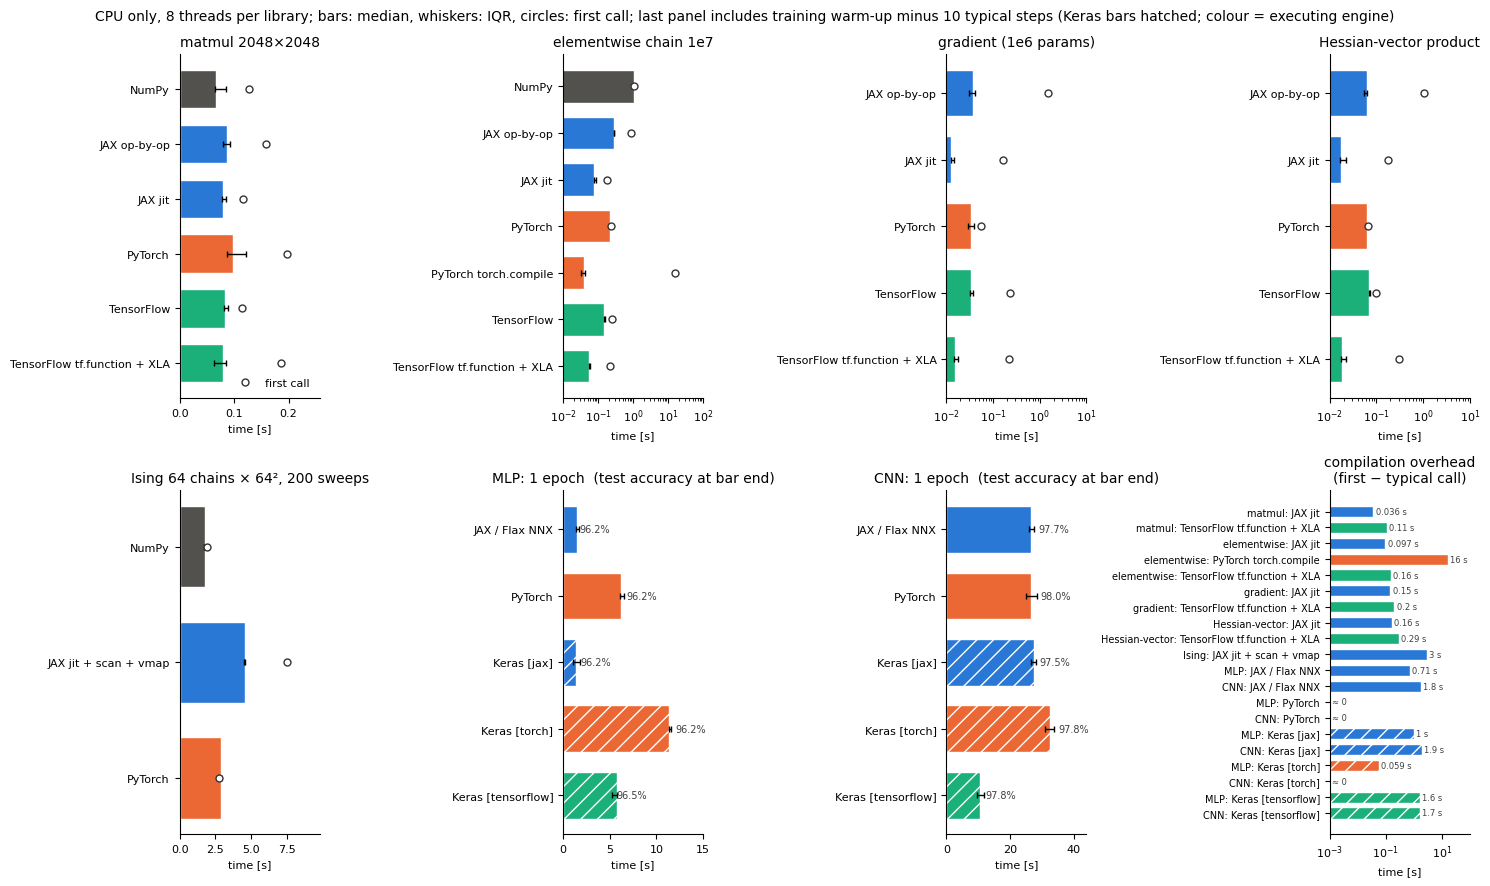

In [17]:
# colour = engine that executes the computation; Keras bars are hatched
COLOR = {"NumPy": "#52514e", "JAX": "#2a78d6", "PyTorch": "#eb6834", "TensorFlow": "#1baf7a"}
def engine(fw):
    if fw.startswith("Keras"):
        return {"jax": "JAX", "torch": "PyTorch", "tensorflow": "TensorFlow"}[fw.split("[")[1][:-1]]
    return fw.split(" ")[0]

from matplotlib.ticker import NullFormatter

def time_axis(ax, values):
    # log scale only when the times span more than a factor of 10; bars then start at a full decade
    v = np.asarray(values, float); v = v[v > 0]
    if v.max() / v.min() > 10:
        ax.set_xscale("log")
        ax.set_xlim(10 ** np.floor(np.log10(v.min())), 10 ** np.ceil(np.log10(v.max() * 1.5)))
        ax.xaxis.set_minor_formatter(NullFormatter())
    else:
        ax.set_xlim(0, v.max() * 1.3)
    ax.set_xlabel("time [s]", fontsize=8); ax.tick_params(axis="x", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)

tasks = list(dict.fromkeys(df["task"]))
fig, axes = plt.subplots(2, 4, figsize=(15, 9))
for ax, task in zip(axes.flat, tasks):
    d = df[df["task"] == task].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    err = np.vstack([d["median_s"] - d["q25_s"], d["q75_s"] - d["median_s"]]).clip(min=0)
    training = "epoch" in task
    time_axis(ax, np.r_[d["median_s"], d["q75_s"]] if training else np.r_[d["median_s"], d["q75_s"], d["first_call_s"]])
    ax.barh(y, d["median_s"], xerr=err, color=[COLOR[engine(f)] for f in d["framework"]],
            hatch=["//" if f.startswith("Keras") else "" for f in d["framework"]], edgecolor="white",
            height=0.7, error_kw=dict(lw=1, capsize=2))
    if not training:
        ax.plot(d["first_call_s"], y, "o", ms=5, mfc="white", mec="0.2", label="first call")
    else:
        for yy, t_, a in zip(y, d["q75_s"], d["test_acc"]):
            ax.text(t_ * 1.04 if ax.get_xscale() == "linear" else t_ * 1.15, yy, f"{100*a:.1f}%",
                    va="center", fontsize=7, color="0.25")
    ax.set_yticks(y); ax.set_yticklabels(d["label"], fontsize=8)
    ax.set_title(task + ("  (test accuracy at bar end)" if training else ""), fontsize=10)
axes.flat[0].legend(fontsize=8, frameon=False, loc="lower right")

# last panel: compilation overhead of the compiled variants
ax = axes.flat[len(tasks)]
c = df[df["variant"].isin(["jit", "tf.function + XLA", "torch.compile", "jit + scan + vmap", "train"])].reset_index(drop=True)
y = np.arange(len(c))[::-1]
FLOOR = 1e-3
time_axis(ax, np.r_[c["compile_overhead_s"].clip(lower=FLOOR), 10 * FLOOR])
ax.barh(y, c["compile_overhead_s"].clip(lower=FLOOR), color=[COLOR[engine(f)] for f in c["framework"]],
        hatch=["//" if f.startswith("Keras") else "" for f in c["framework"]], edgecolor="white", height=0.7)
for yy, v in zip(y, c["compile_overhead_s"]):
    ax.text(max(v, FLOOR) * 1.2, yy, f"{v:.2g} s" if v > FLOOR else "≈ 0", va="center", fontsize=6, color="0.25")
ax.set_yticks(y)
ax.set_yticklabels([f"{t.split(' ')[0].rstrip(':')}: {l}" for t, l in zip(c["task"], c["label"])], fontsize=7)
ax.set_title("compilation overhead\n(first − typical call)", fontsize=10)
for a in axes.flat[len(tasks) + 1:]:
    a.axis("off")
fig.suptitle(f"CPU only, {N_THREADS} threads per library; bars: median, whiskers: IQR, circles: first call; "
             f"last panel includes training warm-up minus 10 typical steps (Keras bars hatched; colour = executing engine)", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Key ratios
The statements in Section 9 refer to these numbers.

In [18]:
def t(task, label, col="median_s"):
    return float(df[(df["task"] == task) & (df["label"] == label)][col].iloc[0])

E, M = "elementwise chain 1e7", "matmul 2048×2048"
GR, HV, IS = "gradient (1e6 params)", "Hessian-vector product", "Ising 64 chains × 64², 200 sweeps"
ratios = {
    "matmul: slowest / fastest median":                    df[df.task == M].median_s.max() / df[df.task == M].median_s.min(),
    "elementwise: NumPy / JAX jit":                       t(E, "NumPy") / t(E, "JAX jit"),
    "elementwise: PyTorch eager / torch.compile":         t(E, "PyTorch") / t(E, "PyTorch torch.compile"),
    "elementwise: TF eager / tf.function + XLA":          t(E, "TensorFlow") / t(E, "TensorFlow tf.function + XLA"),
    "elementwise: torch.compile first call [s]":          t(E, "PyTorch torch.compile", "first_call_s"),
    "elementwise: JAX jit first call [s]":                t(E, "JAX jit", "first_call_s"),
    "gradient: JAX op-by-op / JAX jit":                   t(GR, "JAX op-by-op") / t(GR, "JAX jit"),
    "gradient: PyTorch / JAX jit":                        t(GR, "PyTorch") / t(GR, "JAX jit"),
    "HVP / gradient time, JAX jit":                       t(HV, "JAX jit") / t(GR, "JAX jit"),
    "HVP / gradient time, PyTorch":                       t(HV, "PyTorch") / t(GR, "PyTorch"),
    "HVP / gradient time, TF eager":                      t(HV, "TensorFlow") / t(GR, "TensorFlow"),
    "Ising: NumPy / JAX":                                 t(IS, "NumPy") / t(IS, "JAX jit + scan + vmap"),
    "Ising: PyTorch / JAX":                               t(IS, "PyTorch") / t(IS, "JAX jit + scan + vmap"),
    "Ising: JAX compile overhead [s]":                    t(IS, "JAX jit + scan + vmap", "compile_overhead_s"),
}
for model in ("MLP", "CNN"):
    d = df[df.task == f"{model}: 1 epoch"].set_index("label")
    ratios[f"{model}: slowest / fastest epoch"] = d.median_s.max() / d.median_s.min()
    ratios[f"{model}: fastest = {d.median_s.idxmin()}, slowest = {d.median_s.idxmax()}"] = np.nan
    ratios[f"{model}: test accuracy range (max − min)"] = d.test_acc.max() - d.test_acc.min()
for k, v in ratios.items():
    print(f"{k:60s} {'' if np.isnan(v) else f'{v:8.3g}'}")

LOAD_END = os.getloadavg()[0]
print(f"\ntotal run time of the notebook: {time.perf_counter() - T_START:.0f} s")
print(f"1-minute load average: start {LOAD_START:.1f}, end {LOAD_END:.1f}  (logical cores: {os.cpu_count()}, "
      f"threads per library: {N_THREADS})")

matmul: slowest / fastest median                                 1.48
elementwise: NumPy / JAX jit                                     13.3
elementwise: PyTorch eager / torch.compile                       5.78
elementwise: TF eager / tf.function + XLA                         2.6
elementwise: torch.compile first call [s]                        16.2
elementwise: JAX jit first call [s]                             0.176
gradient: JAX op-by-op / JAX jit                                 2.88
gradient: PyTorch / JAX jit                                      2.68
HVP / gradient time, JAX jit                                     1.33
HVP / gradient time, PyTorch                                     1.81
HVP / gradient time, TF eager                                    2.09
Ising: NumPy / JAX                                              0.391
Ising: PyTorch / JAX                                            0.639
Ising: JAX compile overhead [s]                                  3.01
MLP: slowest / faste

## 9. Trade-offs

The numbers below are from the run stored in this notebook: CPU only, 8 threads per library, 1-minute load average
16.7 at the start and 13.4 at the end on 16 logical cores. Other programs were running. The thread-scaling check in
Section 2 shows it: the PyTorch elementwise chain took 241 ms with 8 threads and 227 ms with 4. A re-run will give
somewhat different times. On a GPU, or with much larger models, the ranking can change.

### 9.1 One large kernel
For a single large kernel the library hardly matters. The $2048\times2048$ matrix multiplication took 66–98 ms in
every library (175–260 GFLOP/s). The slowest-to-fastest ratio is 1.48, comparable with the spread between repeats
(PyTorch IQR 35 ms). Each library passes the work to an optimised linear-algebra kernel.

### 9.2 Many small operations
For many small operations compilation pays off. The elementwise chain on $10^7$ numbers took 1.05 s in NumPy
(NumPy runs elementwise operations on one thread) and 0.15–0.29 s in the eager modes of TensorFlow, PyTorch and JAX.
Compiling the formula into one fused loop cut this to 79 ms (JAX jit), 57 ms (TensorFlow + XLA) and 39 ms
(`torch.compile`). Compared with NumPy, JAX jit is 13× faster; compared with eager PyTorch, `torch.compile` is 5.8× faster.

### 9.3 Cost of compilation
Compilation is not free, and its cost differs by two orders of magnitude between compilers. XLA compilation (JAX jit,
`tf.function + XLA`) added 0.04–0.3 s to the first call. A cold `torch.compile` of the same formula took 16.2 s,
because it generates and compiles C++ code. It saves $226 - 39 = 187$ ms per call, so it pays off only after about
87 calls. JAX also has a cost in op-by-op mode: the first gradient call took 1.5 s, because each primitive is
compiled once per shape.

### 9.4 Automatic differentiation
All libraries compute the same derivatives, at different speeds. Every library reproduced the closed-form
gradient and Hessian–vector product to a relative error below $10^{-6}$. The compiled gradient took 12.8 ms in JAX and
15.3 ms in TensorFlow + XLA, against 34 ms for eager PyTorch and eager TensorFlow. The Hessian–vector product cost 1.3
gradients in JAX jit, 1.8 in PyTorch and 2.1 in eager TensorFlow.

### 9.5 The Ising sampler
The Ising model shows that compilation does not guarantee speed. All three samplers give the same physics: the largest
pairwise deviation is 2.1σ at $T=2.0$ and 0.9σ at $T=3.0$, and $\langle|m|\rangle = 0.911$ matches Onsager–Yang
(0.9113). Here vectorised NumPy was the fastest (1.78 s), ahead of PyTorch (2.91 s) and the compiled JAX version
(4.55 s, plus 3.0 s of compilation). Random numbers explain part of the gap. Generating the same $1.05\times10^8$
uniform numbers alone took 0.54 s in NumPy (PCG64), 1.17 s in PyTorch and 1.91 s in JAX (Threefry), i.e. 42 % of the
JAX run time. In exchange, Threefry gives reproducible, independent streams through `jax.random.split`, and the JAX
code is written for one chain and turned into 64 chains with `vmap`.

### 9.6 Training
Training times are compared at equal accuracy. After one epoch the test accuracies agree within 0.33 percentage
points for the MLP (96.2–96.5 %) and within 0.47 points for the CNN (97.5–98.0 %), so the timings compare the same job.

For the small MLP the per-step overhead dominates. The JAX-based runs, which compile the whole step (Flax NNX 1.52 s,
Keras [jax] 1.42 s per epoch, 3 ms/step), were 3.8–8× faster than eager PyTorch (6.16 s), Keras [tensorflow] (5.73 s) and
Keras [torch] (11.33 s).
For the CNN the quality of the kernels dominates. Keras [tensorflow] was fastest (10.7 s per epoch) although its step was not
XLA-compiled (`model.jit_compile = False`). The XLA-compiled JAX step (26.6 s) was no faster than eager PyTorch (26.6 s).
When convolutions dominate, the speed of the convolution kernels matters more than fusing operations.

The Keras front end has a cost on some backends: Keras [jax] matched Flax NNX within the IQR (1.42 vs 1.52 s, MLP),
while Keras [torch] was 1.8× slower than plain PyTorch (11.33 vs 6.16 s, MLP).
The warm-up took 0.7–1.9 s for the compiled steps (JAX, Keras [jax], Keras [tensorflow]), and at most 0.06 s for eager PyTorch and Keras [torch].

### 9.7 Criteria beyond speed
Speed is one criterion among several, as the table summarises.

| | NumPy | JAX / Flax NNX | PyTorch | Keras 3 |
|---|---|---|---|---|
| Speed of compiled code in this notebook | no compiler; fastest for the Ising sampler | fastest for gradients and HVP (TensorFlow + XLA close behind) and for the MLP step | eager mode competitive for the CNN; `torch.compile` fastest for the elementwise chain | backend-dependent: fastest CNN on TensorFlow |
| Compile time | none | 0.04–3 s here; once per input shape | none in eager mode; 16 s for a cold `torch.compile` | as the backend |
| Flexibility | arrays only, no derivatives | composable transformations: `grad`, `jvp`, `vmap`, `scan` (Sections 3, 4) | derivatives of any Python code run eagerly | high-level `fit`; one model code for three backends (Section 5) |
| Debugging | plain Python | inside `jit` values are tracers; use `jax.debug.print` | plain Python, line by line | errors surface inside `fit`; `run_eagerly=True` |
| Fixed shapes required | no | yes, otherwise recompilation (Exercise 3) | no | no |

No single library wins. Use NumPy for small array code without derivatives. JAX suits code that is transformed —
differentiated, vectorised over chains or parameters, compiled once and run many times. PyTorch suits models whose
structure changes from step to step and code that you debug line by line. Keras suits standard models trained with
`fit`, when the backend should stay a free choice. Measure on your own problem and hardware, with the protocol of
Section 1, before you decide.

## 10. Exercises
1. Repeat Section 2 with `N_THREADS = 1, 2, 4, 8` (restart the kernel each time — thread pools are
   fixed at import). Plot GFLOP/s of the matrix multiplication against the number of threads. Is the elementwise chain
   limited by arithmetic or by memory bandwidth?
2. Time `jax.jit` on the elementwise chain for $N = 10^2, 10^4, 10^6, 10^7$ to see how the benefit of compilation depends on size. For which
   $N$ is the compiled version faster than NumPy *including* its first call?
3. Call `chain_jit` on arrays of 10 different lengths and time each call. Explain the result with the
   rule "JAX compiles once per input shape and dtype". Why does the training loop drop the last incomplete batch?
4. Use `ising_jax` to compute $\langle|m|\rangle$ for 20 temperatures in $[1.5, 3.5]$ and $L = 16, 32, 64$. Where do the curves cross, and how does that compare with $T_c$?
5. Double the channel numbers of the CNN and repeat Section 5. Does the ranking of the libraries change? Relate your answer to the time per step spent in arithmetic versus the per-step overhead of Python.